<a href="https://colab.research.google.com/github/rehim2009book-ui/fairloan/blob/main/fairloan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ucimlrepo

In [2]:
# ===================== CELL 1: load data and make it readable =====================
# What it does: downloads the 1,000 loan applicants, renames the cryptic columns, turns codes into words.
import pandas as pd, numpy as np
from ucimlrepo import fetch_ucirepo

raw = fetch_ucirepo(id=144)
X = raw.data.features.copy()
y_raw = raw.data.targets["class"]          # 1 = good (paid back), 2 = bad

names = {
 "Attribute1":"checking","Attribute2":"duration_months","Attribute3":"credit_history","Attribute4":"purpose",
 "Attribute5":"amount","Attribute6":"savings","Attribute7":"employment","Attribute8":"installment_rate",
 "Attribute9":"personal_status","Attribute10":"other_debtors","Attribute11":"residence_years","Attribute12":"property",
 "Attribute13":"age","Attribute14":"other_plans","Attribute15":"housing","Attribute16":"existing_credits",
 "Attribute17":"job","Attribute18":"people_liable","Attribute19":"telephone","Attribute20":"foreign_worker"}
X = X.rename(columns=names)

# IMPORTANT: the code table printed in the original UCI documentation is wrong for several columns.
# We use the corrected meanings from Groemping (2019), "South German Credit Data: Correcting a Widely Used Data Set".
codes = {
 "checking":{"A11":"no account","A12":"<0","A13":"0-200","A14":">=200 or salary"},
 "credit_history":{"A30":"delays in the past","A31":"critical / credits elsewhere","A32":"no credits / all paid back",
                   "A33":"existing credits paid so far","A34":"all credits here paid back"},
 "purpose":{"A40":"other","A41":"new car","A42":"used car","A43":"furniture","A44":"radio/tv","A45":"appliances",
            "A46":"repairs","A47":"education","A48":"vacation","A49":"retraining","A410":"business"},
 "savings":{"A61":"none/unknown","A62":"<100","A63":"100-500","A64":"500-1000","A65":">=1000"},
 "employment":{"A71":"unemployed","A72":"<1yr","A73":"1-4yr","A74":"4-7yr","A75":">=7yr"},
 "other_debtors":{"A101":"none","A102":"co-applicant","A103":"guarantor"},
 "property":{"A121":"none","A122":"car/other","A123":"savings plan/life insurance","A124":"real estate"},
 "other_plans":{"A141":"bank","A142":"stores","A143":"none"},
 "housing":{"A151":"free","A152":"rent","A153":"own"},      # "free" = lives rent-free, e.g. with family
 "job":{"A171":"unskilled non-resident","A172":"unskilled","A173":"skilled","A174":"management"},
 "telephone":{"A191":"no","A192":"yes"},
 # personal_status (sex cannot be recovered) and foreign_worker (coding unreliable) are left as codes and NOT used.
}
for col, m in codes.items():
    X[col] = X[col].map(m).fillna(X[col])

df = X.copy()
df["approve"] = (y_raw == 1).astype(int)            # 1 = good risk = approve
df["young"] = (df["age"] < 25).astype(int)           # the group we audit
print(df.shape)
df.head()

(1000, 22)


,checking,duration_months,credit_history,purpose,amount,savings,employment,installment_rate,personal_status,other_debtors,...,age,other_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,approve,young
0,no account,6,all credits here paid back,furniture,1169,>=1000,>=7yr,4,A93,none,...,67,none,rent,2,skilled,1,yes,A201,1,0
1,<0,48,no credits / all paid back,furniture,5951,none/unknown,1-4yr,2,A92,none,...,22,none,rent,1,skilled,1,no,A201,0,1
2,>=200 or salary,12,all credits here paid back,repairs,2096,none/unknown,4-7yr,2,A93,none,...,49,none,rent,1,unskilled,2,no,A201,1,0
3,no account,42,no credits / all paid back,used car,7882,none/unknown,4-7yr,2,A93,guarantor,...,45,none,own,1,skilled,2,no,A201,1,0
4,no account,24,existing credits paid so far,other,4870,none/unknown,1-4yr,3,A93,none,...,53,none,own,2,skilled,2,no,A201,0,0


In [3]:
# ===================== CELL 2: look at the data =====================
# What it does: counts people, approvals, and how many are under 25.
print("Applicants:", len(df))
print("Good risk (approve):", df.approve.sum(), "=", f"{df.approve.mean():.0%}")
print("Under 25:", df.young.sum(), " | 25 and over:", (1-df.young).sum())
print("\nReal repayment rate by age group:")
print(df.groupby(df.young.map({1:"under 25",0:"25+"}))["approve"].mean().round(3))
print("\nHousing by age group (share of each group):")
print(pd.crosstab(df.young.map({1:"under 25",0:"25+"}), df["housing"], normalize="index").round(2))

Applicants: 1000
Good risk (approve): 700 = 70%
Under 25: 149  | 25 and over: 851

Real repayment rate by age group:
young
25+         0.719
under 25    0.591
Name: approve, dtype: float64

Housing by age group (share of each group):
housing   free   own  rent
young                     
25+       0.13  0.12  0.75
under 25  0.46  0.03  0.50


In [4]:
# ===================== CELL 3: split + baseline + cost =====================
# What it does: holds back 20% for testing. Baseline = approve everyone. Cost = official 5:1 rule.
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

FEATURES = [c for c in df.columns if c not in ["approve","young","foreign_worker","personal_status"]]
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df["approve"], test_size=0.2, stratify=df["approve"], random_state=42)
young_test = (X_test["age"] < 25).astype(int)

def cost(y_true, y_pred):
    """Bank's money lost. Approving a bad risk costs 5, rejecting a good one costs 1."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    bad_approved = ((y_true==0)&(y_pred==1)).sum()
    good_rejected = ((y_true==1)&(y_pred==0)).sum()
    return 5*bad_approved + 1*good_rejected

def report(name, y_true, y_pred):
    print(f"{name}")
    print(f"  accuracy          {accuracy_score(y_true,y_pred):.1%}")
    print(f"  bad-risk recall   {recall_score(1-np.asarray(y_true),1-np.asarray(y_pred)):.1%}   (share of bad risks we caught)")
    print(f"  cost (5:1 rule)   {cost(y_true,y_pred)}   (lower is better)")

baseline = np.ones(len(y_test), dtype=int)
report("Baseline: approve everyone", y_test, baseline)

Baseline: approve everyone
  accuracy          70.0%
  bad-risk recall   0.0%   (share of bad risks we caught)
  cost (5:1 rule)   300   (lower is better)


In [5]:
# ===================== CELL 4: train two models, pick one =====================
# What it does: logistic regression + random forest. We keep whichever loses less money.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

num_cols = ["duration_months","amount","installment_rate","residence_years","age","existing_credits","people_liable"]
cat_cols = [c for c in FEATURES if c not in num_cols]

def make_pipe(model, features=FEATURES):
    nums = [c for c in num_cols if c in features]; cats = [c for c in cat_cols if c in features]
    pre = ColumnTransformer([("num", StandardScaler(), nums),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cats)])
    return Pipeline([("pre", pre), ("model", model)])

lr = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
rf = make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")).fit(X_train, y_train)

report("\nLogistic regression", y_test, lr.predict(X_test))
report("\nRandom forest",       y_test, rf.predict(X_test))

model = lr if cost(y_test, lr.predict(X_test)) <= cost(y_test, rf.predict(X_test)) else rf
print("\nWe keep:", "logistic regression" if model is lr else "random forest")


Logistic regression
  accuracy          67.0%
  bad-risk recall   68.3%   (share of bad risks we caught)
  cost (5:1 rule)   142   (lower is better)

Random forest
  accuracy          74.0%
  bad-risk recall   36.7%   (share of bad risks we caught)
  cost (5:1 rule)   204   (lower is better)

We keep: logistic regression


In [6]:
# ===================== CELL 5: Audit I - does it approve young people less? =====================
# What it does: approval rate for under-25 vs 25+, on the test set. The gap is our headline number.
pred = model.predict(X_test)
tab = pd.DataFrame({"approved": pred, "group": young_test.map({1:"under 25",0:"25+"})})
rates = tab.groupby("group")["approved"].agg(["mean","count"]).rename(columns={"mean":"approval_rate","count":"people"})
print(rates.round(3))
gap = rates.loc["25+","approval_rate"] - rates.loc["under 25","approval_rate"]
print(f"\nGap: 25+ approved {gap:.1%} more often than under-25s.")
print("(Note: the real repayment rates also differ by age - see cell 2. The question is whether the model's gap is bigger than the data justifies, and what drives it. Cells 6, 7 and 7b answer that.)")

          approval_rate  people
group                          
25+               0.581     172
under 25          0.429      28

Gap: 25+ approved 15.3% more often than under-25s.
(Note: the real repayment rates also differ by age - see cell 2. The question is whether the model's gap is bigger than the data justifies, and what drives it. Cells 6, 7 and 7b answer that.)


In [7]:
# ===================== CELL 6: Audit II - delete age. Is it still unfair? And can the model guess age anyway? =====================
# What it does: (a) retrain WITHOUT the age column, measure the gap again (on the test set AND on all 1,000 via cross-validation).
#               (b) "attacker": a model that tries to guess who is under 25 from the other columns.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

FEATURES_NOAGE = [c for c in FEATURES if c != "age"]
model_noage = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE).fit(X_train[FEATURES_NOAGE], y_train)

def approval_gap(pred, young_flag):
    r = pd.Series(pred).groupby(np.asarray(young_flag)).mean()
    return r[0] - r[1]            # 25+ rate minus under-25 rate

pred_noage = model_noage.predict(X_test[FEATURES_NOAGE])
gap_noage = approval_gap(pred_noage, young_test)
print("TEST SET (200 people, only 28 under 25 - noisy):")
print(f"  gap WITH age column:    {gap:.1%}")
print(f"  gap WITHOUT age column: {gap_noage:.1%}")
print(f"  cost without age: {cost(y_test, pred_noage)}  (with age: {cost(y_test, pred)})")

# steadier: predict every one of the 1,000 people with cross-validation (each person predicted by a model that never saw them)
cv_with    = cross_val_predict(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")), df[FEATURES], df["approve"], cv=5)
cv_without = cross_val_predict(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE), df[FEATURES_NOAGE], df["approve"], cv=5)
gap_cv_with, gap_cv_without = approval_gap(cv_with, df["young"]), approval_gap(cv_without, df["young"])
print("\nALL 1,000 PEOPLE (149 under 25, cross-validated):")
print(f"  gap WITH age column:    {gap_cv_with:.1%}")
print(f"  gap WITHOUT age column: {gap_cv_without:.1%}")
if gap_cv_without > 0.5*gap_cv_with:
    print("  -> deleting age removes less than half the gap. The model finds age another way.")
elif gap_cv_without > 0.02:
    print("  -> deleting age shrinks the gap, but a real gap remains. The model finds age another way.")
else:
    print("  -> deleting age closes most of the gap in this data.")

# (b) attacker: guess 'young' from everything except age
attacker = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE)
guess = cross_val_predict(attacker, df[FEATURES_NOAGE], df["young"], cv=5, method="predict_proba")[:,1]
auc = roc_auc_score(df["young"], guess)
print(f"\nAttacker AUC for guessing 'under 25' without seeing age: {auc:.2f}   (0.50 = coin flip, 1.00 = perfect)")

attacker.fit(df[FEATURES_NOAGE], df["young"])
feat_names = attacker.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(attacker.named_steps["model"].coef_[0], index=feat_names)
print("\nTop clues that someone is YOUNG:");  print(coefs.sort_values(ascending=False).head(6).round(2))
print("\nTop clues that someone is OLDER:"); print(coefs.sort_values().head(6).round(2))

TEST SET (200 people, only 28 under 25 - noisy):
  gap WITH age column:    15.3%
  gap WITHOUT age column: 7.0%
  cost without age: 148  (with age: 142)

ALL 1,000 PEOPLE (149 under 25, cross-validated):
  gap WITH age column:    17.4%
  gap WITHOUT age column: 13.8%
  -> deleting age removes less than half the gap. The model finds age another way.

Attacker AUC for guessing 'under 25' without seeing age: 0.78   (0.50 = coin flip, 1.00 = perfect)

Top clues that someone is YOUNG:
cat__housing_free           1.20
cat__purpose_appliances     0.83
cat__job_skilled            0.57
cat__employment_<1yr        0.56
cat__purpose_radio/tv       0.46
cat__checking_no account    0.43
dtype: float64

Top clues that someone is OLDER:
cat__job_management             -1.14
cat__employment_>=7yr           -1.03
cat__purpose_retraining         -0.76
cat__housing_own                -0.73
cat__purpose_business           -0.65
cat__checking_>=200 or salary   -0.56
dtype: float64


        feature             young-typical vs older-typical             kind flips (everyone) flips (real under-25s)          who loses
       checking                      <0 vs >=200 or salary            money              40%                    48%         first twin
        housing                               free vs rent stand-in for age              13%                    14% young-typical twin
       property savings plan/life insurance vs real estate stand-in for age              13%                    11% older-typical twin
        savings                             <100 vs >=1000            money               9%                     9%         first twin
     employment                              <1yr vs >=7yr stand-in for age               8%                     9% young-typical twin
      telephone                                  no vs yes stand-in for age               7%                     7% young-typical twin
            job                      skilled vs managem

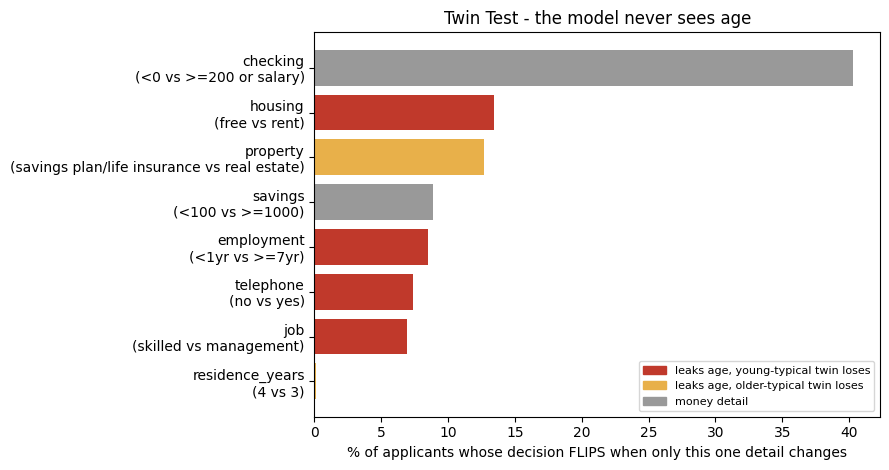


Strongest age stand-in that works AGAINST the young-typical twin: housing (free vs rent) - flips the decision for 13% of applicants. The model was never told anyone's age.

Leyla, applicant #93 (housing: free):  approve chance 47%  -> REJECTED
Her twin (housing: rent):  approve chance 61%  -> APPROVED
Everything else about them is identical. The model was never told their age.

Real under-25s with housing = free who are rejected, but would be approved with housing = rent: 7 of 69


In [8]:
# ===================== CELL 7: Audit III - the Twin Test =====================
# What it does: for each detail, every applicant gets an identical twin that differs ONLY in that detail.
# One twin gets the value most typical of under-25s, the other the value most typical of over-25s.
# (The data picks those values, not us.) We count how often the age-free model changes its answer.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

is_young = df["young"].values.astype(bool)

def typical_pair(feature):
    """Value most over-represented among under-25s, and value most over-represented among 25+."""
    sy = df.loc[is_young, feature].value_counts(normalize=True)
    so = df.loc[~is_young, feature].value_counts(normalize=True)
    idx = sy.index.union(so.index)
    diff = sy.reindex(idx, fill_value=0) - so.reindex(idx, fill_value=0)
    return diff.idxmax(), diff.idxmin()

STAND_INS = ["housing", "employment", "job", "telephone", "property", "residence_years"]   # details that can leak age
MONEY = [("savings", "<100", ">=1000"), ("checking", "<0", ">=200 or salary")]              # details a bank may fairly use

pairs = [(f, *typical_pair(f), "stand-in for age") for f in STAND_INS] + [(f, a, b, "money") for f, a, b in MONEY]

rows = []
for f, yv, ov, kind in pairs:
    a = df[FEATURES_NOAGE].copy(); a[f] = yv          # young-typical twin
    b = df[FEATURES_NOAGE].copy(); b[f] = ov          # older-typical twin
    pa, pb = model_noage.predict(a), model_noage.predict(b)
    flips = pa != pb
    young_twin_loses = ((pa == 0) & (pb == 1)).mean(); old_twin_loses = ((pa == 1) & (pb == 0)).mean()
    rows.append({"feature": f, "young-typical vs older-typical": f"{yv} vs {ov}", "kind": kind,
                 "flips (everyone)": flips.mean(), "flips (real under-25s)": flips[is_young].mean(),
                 "who loses": ("first twin" if young_twin_loses >= old_twin_loses else "second twin") if kind == "money"
                              else ("young-typical twin" if young_twin_loses >= old_twin_loses else "older-typical twin")})
twins = pd.DataFrame(rows).sort_values("flips (everyone)", ascending=False).reset_index(drop=True)
print(twins.to_string(index=False, formatters={"flips (everyone)":"{:.0%}".format, "flips (real under-25s)":"{:.0%}".format}))

def bar_color(r):
    if r["kind"] == "money": return "#999999"
    return "#c0392b" if r["who loses"] == "young-typical twin" else "#e8b04a"
plt.figure(figsize=(9,4.8))
plt.barh(twins["feature"] + "\n(" + twins["young-typical vs older-typical"] + ")", twins["flips (everyone)"]*100,
         color=[bar_color(r) for _, r in twins.iterrows()])
plt.gca().invert_yaxis()
plt.xlabel("% of applicants whose decision FLIPS when only this one detail changes")
plt.title("Twin Test - the model never sees age")
plt.legend(handles=[Patch(color="#c0392b", label="leaks age, young-typical twin loses"),
                    Patch(color="#e8b04a", label="leaks age, older-typical twin loses"),
                    Patch(color="#999999", label="money detail")], loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

hurts = twins[(twins.kind == "stand-in for age") & (twins["who loses"] == "young-typical twin")]
if len(hurts):
    top = hurts.iloc[0]
    print(f"\nStrongest age stand-in that works AGAINST the young-typical twin: {top['feature']} ({top['young-typical vs older-typical']})"
          f" - flips the decision for {top['flips (everyone)']:.0%} of applicants. The model was never told anyone's age.")
    # One concrete twin for the demo: a real under-25 whose decision flips when only that detail changes
    f = top["feature"]; yv, ov = [p for p in pairs if p[0] == f][0][1:3]
    cands = df[is_young & (df[f] == yv)][FEATURES_NOAGE]
    cands_twin = cands.copy(); cands_twin[f] = ov
    flipped = (model_noage.predict(cands) == 0) & (model_noage.predict(cands_twin) == 1)
    leyla = cands[flipped].iloc[[0]] if flipped.any() else cands.iloc[[0]]
    twin  = leyla.copy(); twin[f] = ov
    p1 = model_noage.predict_proba(leyla)[0,1]; p2 = model_noage.predict_proba(twin)[0,1]
    print(f"\nLeyla, applicant #{leyla.index[0]} ({f}: {yv}):  approve chance {p1:.0%}  -> {'APPROVED' if p1>=0.5 else 'REJECTED'}")
    print(f"Her twin ({f}: {ov}):  approve chance {p2:.0%}  -> {'APPROVED' if p2>=0.5 else 'REJECTED'}")
    print("Everything else about them is identical. The model was never told their age.")
    print(f"\nReal under-25s with {f} = {yv} who are rejected, but would be approved with {f} = {ov}: {flipped.sum()} of {len(cands)}")
else:
    leyla = df[is_young & (model_noage.predict(df[FEATURES_NOAGE]) == 0)].iloc[[0]][FEATURES_NOAGE]
    print("\nNo age stand-in works against the young-typical twin in this model.")

In [9]:
# ===================== CELL 7b: the fair question - among people who really PAID BACK, who got wrongly rejected? =====================
# What it does: young people in this data repay a bit less often, so some gap is expected.
# The fair test is: look ONLY at people who did pay back. Does the model wrongly reject the young ones more often?
good = df["approve"].values == 1
print(f"People who really paid back: {(good & is_young).sum()} under 25, {(good & ~is_young).sum()} aged 25+\n")
for label, p in [("model WITH age", cv_with), ("model WITHOUT age", cv_without)]:
    wrong_young = (p[good & is_young] == 0).mean()
    wrong_old   = (p[good & ~is_young] == 0).mean()
    print(f"{label}:")
    print(f"   good payers wrongly rejected, under 25: {wrong_young:.1%}")
    print(f"   good payers wrongly rejected, 25+:      {wrong_old:.1%}")
    print(f"   -> a young good payer is {wrong_young/wrong_old:.1f}x as likely to be wrongly rejected\n")
print(f"For comparison, real repayment rates: under 25 {df.approve[is_young].mean():.1%}, 25+ {df.approve[~is_young].mean():.1%}")

People who really paid back: 88 under 25, 612 aged 25+

model WITH age:
   good payers wrongly rejected, under 25: 39.8%
   good payers wrongly rejected, 25+:      25.8%
   -> a young good payer is 1.5x as likely to be wrongly rejected

model WITHOUT age:
   good payers wrongly rejected, under 25: 37.5%
   good payers wrongly rejected, 25+:      26.8%
   -> a young good payer is 1.4x as likely to be wrongly rejected

For comparison, real repayment rates: under 25 59.1%, 25+ 71.9%


In [10]:
# ===================== CELL 8: the fix - make the bot fairer, and show what it costs the bank =====================
# What it does: tries two simple fixes and scores every version on money (5:1 rule) and on fairness.
#   Fix A: also delete the details that leak age and work against young people (found by the Twin Test).
#   Fix B: keep the model, but use a slightly lower pass mark for under-25s, so that good payers of both
#          age groups are wrongly rejected about equally often. The pass mark is picked on other people's data.
# All numbers are for all 1,000 applicants, each one scored by a model that never saw them (cross-validation).
from sklearn.model_selection import StratifiedKFold

y_all = df["approve"].values
def new_lr(): return LogisticRegression(max_iter=2000, class_weight="balanced")

proba_noage = cross_val_predict(make_pipe(new_lr(), FEATURES_NOAGE), df[FEATURES_NOAGE], df["approve"], cv=5, method="predict_proba")[:, 1]

# Fix A: drop the age stand-ins that hurt the young-typical twin (flip rate of 5% or more)
DROP = hurts.loc[hurts["flips (everyone)"] >= 0.05, "feature"].tolist()
FEATURES_A = [c for c in FEATURES_NOAGE if c not in DROP]
pred_A = cross_val_predict(make_pipe(new_lr(), FEATURES_A), df[FEATURES_A], df["approve"], cv=5)
print("Fix A deletes these details:", DROP if DROP else "(none found)")

# Fix B: lower pass mark for under-25s
def young_pass_mark(p, y, young):
    target = (p[(y == 1) & ~young] < 0.5).mean()                    # how often older good payers are wrongly rejected
    marks = np.arange(0.20, 0.505, 0.01)
    rates = np.array([(p[(y == 1) & young] < m).mean() for m in marks])
    return float(marks[np.argmin(np.abs(rates - target))])

pred_B = (proba_noage >= 0.5).astype(int); marks_used = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(proba_noage, y_all):
    m = young_pass_mark(proba_noage[tr], y_all[tr], is_young[tr]); marks_used.append(m)
    te_young = te[is_young[te]]
    pred_B[te_young] = (proba_noage[te_young] >= m).astype(int)
print(f"Fix B pass mark for under-25s: about {np.mean(marks_used):.2f} (everyone else: 0.50)\n")

def summary(name, p):
    p = np.asarray(p)
    return {"version": name, "cost": cost(y_all, p), "accuracy": (p == y_all).mean(),
            "approval gap": approval_gap(p, df["young"]),
            "good payers wrongly rejected, under 25": (p[(y_all == 1) & is_young] == 0).mean(),
            "same, 25+": (p[(y_all == 1) & ~is_young] == 0).mean()}

results = pd.DataFrame([
    summary("approve everyone", np.ones(len(df), dtype=int)),
    summary("model with age", cv_with),
    summary("model without age", cv_without),
    summary("Fix A: also delete age stand-ins", pred_A),
    summary("Fix B: lower pass mark under 25", pred_B),
])
pct = "{:.1%}".format
print(results.to_string(index=False, formatters={"accuracy": pct, "approval gap": pct,
      "good payers wrongly rejected, under 25": pct, "same, 25+": pct}))

base = results.iloc[2]
for i in [3, 4]:
    r = results.iloc[i]
    print(f"\n{r['version']}: cost {base['cost']} -> {r['cost']} ({r['cost']-base['cost']:+d}), "
          f"approval gap {base['approval gap']:.1%} -> {r['approval gap']:.1%}, "
          f"young good payers wrongly rejected {base['good payers wrongly rejected, under 25']:.1%} -> {r['good payers wrongly rejected, under 25']:.1%}")
print("\n(Cost: approving a bad risk = 5, rejecting a good one = 1. Lower is better. 'approve everyone' is the baseline.)")

Fix A deletes these details: ['housing', 'employment', 'telephone', 'job']
Fix B pass mark for under-25s: about 0.30 (everyone else: 0.50)

                         version  cost accuracy approval gap good payers wrongly rejected, under 25 same, 25+
                approve everyone  1500    70.0%         0.0%                                   0.0%      0.0%
                  model with age   613    72.3%        17.4%                                  39.8%     25.8%
               model without age   617    71.9%        13.8%                                  37.5%     26.8%
Fix A: also delete age stand-ins   603    71.7%        10.2%                                  36.4%     27.9%
 Fix B: lower pass mark under 25   708    70.8%        -5.7%                                  27.3%     26.8%

Fix A: also delete age stand-ins: cost 617 -> 603 (-14), approval gap 13.8% -> 10.2%, young good payers wrongly rejected 37.5% -> 36.4%

Fix B: lower pass mark under 25: cost 617 -> 708 (+91), approv

In [11]:
# ===================== CELL 9: what would get me a yes? =====================
# What it does: for a rejected person, tries small realistic changes and reports the smallest one that turns the
# answer into a yes. It never suggests "be older". It shows what flips THIS model - it is not a promise from a bank.
from itertools import combinations

SAVINGS_ORDER  = ["none/unknown", "<100", "100-500", "500-1000", ">=1000"]
CHECKING_ORDER = ["<0", "0-200", ">=200 or salary"]
EMPLOY_ORDER   = ["unemployed", "<1yr", "1-4yr", "4-7yr", ">=7yr"]

def possible_changes(person):
    """List of (feature, new value, plain text, effort). Lower effort = smaller change."""
    r = person.iloc[0]; out = []
    for k, cut in enumerate([10, 20, 30, 40, 50], start=1):
        new = int(round(r["amount"] * (1 - cut / 100)))
        out.append(("amount", new, f"ask for {cut}% less money ({int(r['amount'])} -> {new} DM)", k))
    k = 1
    while r["duration_months"] - 6 * k >= 6:
        new = int(r["duration_months"] - 6 * k)
        out.append(("duration_months", new, f"pay it back faster ({int(r['duration_months'])} -> {new} months)", k)); k += 1
    if r["savings"] in SAVINGS_ORDER:
        i = SAVINGS_ORDER.index(r["savings"])
        for j in range(i + 1, len(SAVINGS_ORDER)):
            out.append(("savings", SAVINGS_ORDER[j], f"build savings from '{r['savings']}' to '{SAVINGS_ORDER[j]}' DM", j - i))
    if r["checking"] in CHECKING_ORDER:
        i = CHECKING_ORDER.index(r["checking"])
        for j in range(i + 1, len(CHECKING_ORDER)):
            out.append(("checking", CHECKING_ORDER[j], f"bring the checking account from '{r['checking']}' to '{CHECKING_ORDER[j]}' DM", j - i))
    if r["other_debtors"] != "guarantor":
        out.append(("other_debtors", "guarantor", "add a guarantor (someone who promises to pay if you cannot)", 2))
    if r["employment"] in EMPLOY_ORDER[:-1]:
        nxt = EMPLOY_ORDER[EMPLOY_ORDER.index(r["employment"]) + 1]
        out.append(("employment", nxt, f"stay in your job until it counts as '{nxt}' (takes time)", 3))
    return out

def recourse(person, max_options=2):
    """Returns a list of plain-text options that would turn a 'no' into a 'yes'. Empty list = nothing small is enough."""
    person = person[FEATURES_NOAGE]
    if model_noage.predict(person)[0] == 1: return []
    changes = possible_changes(person)
    if not changes: return []
    singles = pd.concat([person] * len(changes), ignore_index=True)
    for i, (f, v, _, _) in enumerate(changes): singles.at[i, f] = v
    ok = model_noage.predict(singles) == 1
    best = {}                                             # smallest working change per detail
    for (f, v, text, effort), good in zip(changes, ok):
        if good and (f not in best or effort < best[f][1]): best[f] = (text, effort)
    if best:
        return [t for t, _ in sorted(best.values(), key=lambda x: x[1])[:max_options]]
    pairs = [(a, b) for a, b in combinations(changes, 2) if a[0] != b[0]]       # no single change works: try two together
    if not pairs: return []
    doubles = pd.concat([person] * len(pairs), ignore_index=True)
    for i, (a, b) in enumerate(pairs): doubles.at[i, a[0]] = a[1]; doubles.at[i, b[0]] = b[1]
    ok2 = model_noage.predict(doubles) == 1
    working = sorted([(a[3] + b[3], f"{a[2]} AND {b[2]}") for (a, b), good in zip(pairs, ok2) if good])
    return [t for _, t in working[:1]]

rejected_ids = df.index[model_noage.predict(df[FEATURES_NOAGE]) == 0]
show = [leyla.index[0]] + [i for i in rejected_ids if i != leyla.index[0]][:2]
for pid in show:
    p = df.loc[[pid]]
    print(f"Applicant #{pid} (approve chance {model_noage.predict_proba(p[FEATURES_NOAGE])[0,1]:.0%}):")
    opts = recourse(p)
    if model_noage.predict(p[FEATURES_NOAGE])[0] == 1: print("   already approved")
    elif opts:
        for o in opts: print("   would get a yes if they:", o)
    else: print("   no small change is enough")

# How many rejected people have a way to a yes? Compare the age groups.
has_way = pd.Series({pid: len(recourse(df.loc[[pid]])) > 0 for pid in rejected_ids})
grp = df.loc[rejected_ids, "young"].map({1: "under 25", 0: "25+"})
print("\nRejected people who have at least one small change that leads to a yes:")
print(pd.DataFrame({"has a way": has_way.groupby(grp).mean().round(3), "rejected people": has_way.groupby(grp).size()}))

Applicant #93 (approve chance 47%):
   would get a yes if they: pay it back faster (24 -> 18 months)
   would get a yes if they: bring the checking account from '0-200' to '>=200 or salary' DM
Applicant #1 (approve chance 24%):
   would get a yes if they: bring the checking account from '<0' to '>=200 or salary' DM
   would get a yes if they: add a guarantor (someone who promises to pay if you cannot)
Applicant #4 (approve chance 9%):
   would get a yes if they: build savings from 'none/unknown' to '500-1000' DM AND add a guarantor (someone who promises to pay if you cannot)

Rejected people who have at least one small change that leads to a yes:
          has a way  rejected people
young                               
25+           0.914              337
under 25      0.939               82


In [12]:
!pip install -q -U google-genai

In [13]:
# ===================== CELL 10: the explainer - why did I get this answer? =====================
# What it does: (a) finds the 3 details that pushed THIS person's decision the most,
#               (b) asks Gemini to turn them into 3 plain sentences,
#               (c) saves every answer to explanations.json so the notebook also runs with no API key.
import json, os

USE_API = True                       # set to False to use only saved answers (what judges will get)
CACHE_FILE = "explanations.json"
GEMINI_MODELS = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite", "gemini-2.5-flash"]   # tried in this order

PLAIN = {"checking":"checking account balance", "duration_months":"loan length (months)", "credit_history":"credit history",
         "purpose":"loan purpose", "amount":"loan amount", "savings":"savings", "employment":"time in current job",
         "installment_rate":"share of income going to repayments", "other_debtors":"co-applicant or guarantor",
         "residence_years":"years at current address", "property":"property owned", "other_plans":"other payment plans",
         "housing":"housing (rent / own / free)", "existing_credits":"number of existing loans", "job":"job type",
         "people_liable":"number of dependants", "telephone":"registered telephone"}

# ---- (a) the model's real reasons ----
_pre, _clf = model_noage.named_steps["pre"], model_noage.named_steps["model"]
_names = list(_pre.get_feature_names_out())
_avg = np.asarray(_pre.transform(X_train[FEATURES_NOAGE]).mean(axis=0)).ravel() * _clf.coef_[0]   # the average applicant

def _owner(col_name):
    """Which original column does this model input belong to?"""
    if col_name.startswith("num__"): return col_name[5:]
    for c in sorted(FEATURES_NOAGE, key=len, reverse=True):
        if col_name.startswith(f"cat__{c}_"): return c
    return col_name

def top_drivers(person, k=3):
    """Returns the decision, the approve chance, and the k details that pushed hardest toward that decision."""
    xt = _pre.transform(person[FEATURES_NOAGE])
    xt = np.asarray(xt.todense()).ravel() if hasattr(xt, "todense") else np.asarray(xt).ravel()
    push = pd.Series(xt * _clf.coef_[0] - _avg, index=[_owner(n) for n in _names]).groupby(level=0).sum()
    prob = model_noage.predict_proba(person[FEATURES_NOAGE])[0, 1]
    approved = prob >= 0.5
    ranked = push.sort_values(ascending=not approved)          # rejected -> most negative first
    drivers = [{"feature": f, "plain": PLAIN.get(f, f), "value": str(person.iloc[0][f]),
                "effect": "helped" if v > 0 else "hurt", "strength": round(float(v), 2)}
               for f, v in ranked.head(k).items()]
    return approved, prob, drivers

# ---- (b) Gemini writes it in plain words ----
def build_prompt(approved, drivers):
    lines = "\n".join(f"- {d['plain']}: {d['value']} ({d['effect']} the application)" for d in drivers)
    return (f"A bank's computer model {'APPROVED' if approved else 'REJECTED'} a loan application.\n"
            f"These are the ONLY reasons the model used, strongest first:\n{lines}\n\n"
            "Write exactly 3 short sentences to the applicant, in plain everyday English a 15-year-old understands.\n"
            "Rules: use ONLY the reasons listed above. Do not add any other reason. Do not mention age, sex or nationality. "
            "Do not promise anything. No greeting, no sign-off.")

def template_text(approved, drivers):
    parts = ", ".join(f"{d['plain']} ({d['value']})" for d in drivers)
    return f"[template, no AI] Your application was {'approved' if approved else 'rejected'}. The details that mattered most were: {parts}."

_client = None
def ask_gemini(prompt):
    """Returns (text, model_name) or (None, None) if the API is not available."""
    global _client
    if not USE_API: return None, None
    try:
        from google import genai
        if _client is None:
            try:
                from google.colab import userdata
                key = userdata.get("GEMINI_API_KEY")
            except Exception:
                key = os.environ.get("GEMINI_API_KEY")
            if not key: print("No GEMINI_API_KEY found - using saved answers / template."); return None, None
            _client = genai.Client(api_key=key)
        for m in list(GEMINI_MODELS):
            try:
                text = _client.models.generate_content(model=m, contents=prompt).text.strip()
                GEMINI_MODELS.remove(m); GEMINI_MODELS.insert(0, m)      # remember the one that works
                return text, m
            except Exception as e:
                print(f"  ({m} failed: {str(e)[:80]})")
    except Exception as e:
        print("Gemini not available:", str(e)[:100])
    return None, None

# ---- (c) cache ----
cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}

def explain(person_id):
    """person_id = row number in df. Returns a dict with decision, drivers and the explanation text."""
    key = str(person_id)
    if key in cache: return cache[key]
    person = df.loc[[person_id]]
    approved, prob, drivers = top_drivers(person)
    text, used = ask_gemini(build_prompt(approved, drivers))
    out = {"decision": "APPROVED" if approved else "REJECTED", "approve_chance": round(float(prob), 2),
           "drivers": drivers, "text": text or template_text(approved, drivers), "written_by": used or "template"}
    if text:                                   # only save real AI answers
        cache[key] = out
        json.dump(cache, open(CACHE_FILE, "w"), indent=1)
    return out

# ---- try it on Leyla and on one approved person ----
approved_id = int(df.index[model_noage.predict(df[FEATURES_NOAGE]) == 1][0])
for pid in [int(leyla.index[0]), approved_id]:
    r = explain(pid)
    print(f"Applicant #{pid}: {r['decision']} (approve chance {r['approve_chance']:.0%})   [written by: {r['written_by']}]")
    for d in r["drivers"]:
        print(f"   model's real reason: {d['plain']} = {d['value']}  ({d['effect']}, strength {d['strength']})")
    print("   " + r["text"] + "\n")
print(f"Saved answers in {CACHE_FILE}: {len(cache)}")

Applicant #93: REJECTED (approve chance 47%)   [written by: gemini-3.5-flash-lite]
   model's real reason: property owned = real estate  (hurt, strength -0.47)
   model's real reason: housing (rent / own / free) = free  (hurt, strength -0.47)
   model's real reason: co-applicant or guarantor = co-applicant  (hurt, strength -0.28)
   Your loan was turned down because you own real estate property. Having free housing also hurt your application. Finally, having a co-applicant worked against you.

Applicant #0: APPROVED (approve chance 87%)   [written by: gemini-3.5-flash-lite]
   model's real reason: credit history = all credits here paid back  (helped, strength 0.62)
   model's real reason: savings = >=1000  (helped, strength 0.57)
   model's real reason: loan length (months) = 6  (helped, strength 0.43)
   Your credit history helped because you paid back all your previous credits. Having savings of 1000 or more also helped your application. Finally, your short loan length of 6 months wo